# 23 — Ensayo general de la cadena completa sobre ES2015

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md) ·
[ADR 0010](../docs/decisions/0010-adr-decisiones-del-analisis-del-experimento-b.md) ·
[ADR 0017](../docs/decisions/0017-adr-medicion-de-h4.md) ·
[ADR 0018](../docs/decisions/0018-adr-medicion-de-h2-y-h3.md) · issue #255

**Alcance.** Registro del ensayo general de la cadena completa con el diseño vigente, sobre la
serie de desarrollo ES2015, con una sola corrida y las 21 preguntas de calibración. **No es el
experimento**: ninguna cifra de este notebook es un resultado ni se puede citar como tal. Sirve
para comprobar que las piezas encajan antes del congelamiento y para dejar a la vista qué
produce cada paso.

Todo se lee de las salidas guardadas del ensayo (`reports/experiment-a/ensayo-es2015/`,
`reports/experiment-b/ensayo-b-es2015/` y `reports/tables/ensayo-es2015-*`); el notebook no
calcula estadística nueva ni llama a ningún modelo.

## Los términos, en simple

| Término | Qué significa |
|---|---|
| Ensayo general | Correr toda la cadena una vez, con los mismos comandos del experimento, sobre una serie de desarrollo. |
| C0, C1, C2, C3 | C0 responde sin ningún contexto; C1 recupera texto de las transcripciones; C2 consulta la base compilada por la máquina; C3 consulta la base compilada con las decisiones de oro. |
| E1 a E4 | Tipos de pregunta: E1 decisión puntual, E2 qué versión prevalece, E3 evolución o relación entre decisiones, E4 pregunta sin respuesta en el corpus. |
| Veredicto | Lectura de una hipótesis (respaldada, contraria o no concluyente). Con muestra por debajo del mínimo prerregistrado de 25 preguntas se informa «muestra insuficiente». |

---

# 1. La cadena y sus pasos

**Qué se hace.** Se listan los comandos corridos, en orden, con su duración y resultado.

In [1]:
import pandas as pd
from IPython.display import Image, display

from afg.experiments.rehearsal_summary import (
    correctness_frame,
    load_development_json,
    load_rehearsal_table,
    steps_frame,
    verdict_frame,
)
from afg.shared.paths import EXPERIMENT_A_DIR, EXPERIMENT_B_DIR, FIGURES_DIR, TABLES_DIR

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

A_RUN, B_RUN, NAME = "ensayo-es2015", "ensayo-b-es2015", "ensayo-es2015"
a_report = load_development_json(EXPERIMENT_A_DIR / A_RUN / "informe-descriptivo.json")
b_analysis = load_development_json(EXPERIMENT_B_DIR / B_RUN / "analisis-descriptivo.json")
steps_frame()

,Paso,Comando,Duración,Resultado
0,1. Extracción de C2,afg experiment a --series ES2015 --runs 1 --run-name ensayo-es2015,25 min 47 s,ok: 71 decisiones
1,2. Relaciones,afg experiment a-relations --c2-extraction ensayo-es2015 --run-revisions,2 min 52 s,ok
2,3. Informe de A,afg experiment a-report --c2-extraction ensayo-es2015 --descriptive,10 s,ok
3,4. Base de C3,afg c3 build --c2-extraction ensayo-es2015 --series ES2015 --runs 1,15 s,ok: 27 decisiones de oro
4,5. Experimento B,"afg experiment b --conditions c0,c1,c2,c3 --c2-extraction ensayo-es2015 --run-name ens...",27 min 30 s,"ok: 84 registros, 0 errores"
5,6a. Informe de B,afg experiment b-report --run-name ensayo-b-es2015 --descriptive --questions ...,2 s,ok
6,6b. Hoja OE4,afg experiment b-oe4-sheet --run-name ensayo-b-es2015,1 s,ok: 14 filas
7,6c. Muestra humana,afg experiment b-sample --run-name ensayo-b-es2015,1 s,ok: 24 filas
8,6d. Resumen OE4 y acuerdo juez-humano,afg experiment b-oe4-summary / b-human-check,-,omitido: requiere etiquetas humanas
9,7. Tablas finales,afg experiment final-tables --name ensayo-es2015 --descriptive,1 s,ok: 6 tablas y 3 figuras


**Lectura.** La cadena corrió de punta a punta, sin errores, con una corrida por configuración
(el ensayo no exige las tres corridas del experimento). Los pasos largos son la extracción de
C2 (unos 26 minutos) y el Experimento B (unos 28 minutos); el resto se resuelve en segundos o
pocos minutos. Los pasos de etiquetado humano (resumen OE4 y acuerdo juez-humano) no se corren
porque dependen de etiquetas que solo puede poner una persona.

---

# 2. Experimento A: extracción

**Pregunta.** ¿Qué tanto de la referencia de oro recupera la extracción de C2 con una corrida?

**Qué se muestra.** Precision, recall y F1 con intervalos por conglomerado de reunión, para τ = 0,70 (principal) y las sensibilidades de 0,75 y 0,80.

In [2]:
headline = load_rehearsal_table(TABLES_DIR / f"{NAME}-a-headline.csv")
shown = headline[headline["tau"].isin([0.7, 0.75, 0.8]) & (headline["scope"] == "origin_meetings")]
shown[
    ["tau", "reading", "precision", "recall", "f1", "f1_lower", "f1_upper", "null_coverage"]
].round(2)

,tau,reading,precision,recall,f1,f1_lower,f1_upper,null_coverage
0,0.70,principal,0.13,0.33,0.18,0.08,0.27,0.14
2,0.75,sensibilidad,0.10,0.26,0.14,0.08,0.17,0.05
4,0.80,sensibilidad,0.04,0.11,0.06,0.00,0.11,0.02


In [3]:
relations = load_rehearsal_table(TABLES_DIR / f"{NAME}-a-relations.csv")
relations[["metric", "view", "successes", "trials", "rate"]].round(2)

,metric,view,successes,trials,rate
0,existence_end_to_end,precision,0,26,0.0
1,existence_end_to_end,recall,0,3,0.0
2,existence_conditional,precision,0,0,NaN
3,existence_conditional,recall,0,0,NaN
4,type_principal,end_to_end,0,3,0.0
5,type_principal,conditional,0,0,NaN
6,type_principal,among_detected,0,0,NaN
7,type_strict,end_to_end,0,3,0.0
8,type_strict,conditional,0,0,NaN
9,type_strict,among_detected,0,0,NaN


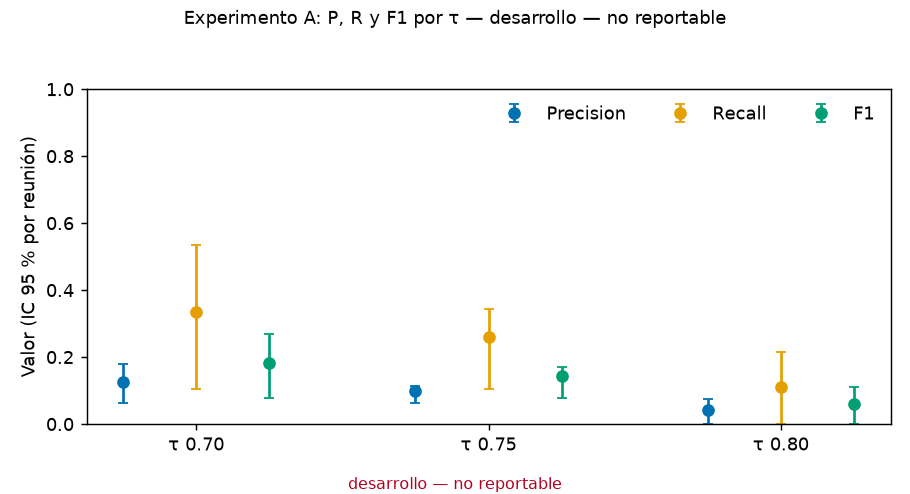

In [4]:
display(Image(filename=str(FIGURES_DIR / f"{NAME}-a-headline.png")))

**Lectura.** Con τ = 0,70 el F1 es bajo (0,18) y apenas supera el piso nulo (0,14). Ninguna de
las tres relaciones de oro quedó alineada con las 26 relaciones de la máquina, así que la
existencia, el tipo y la dirección de las relaciones puntúan en cero. Es una sola corrida con
un generador local pequeño: sirve para ver que el informe se produce, no para juzgar la
extracción.

---

# 3. Experimento B: corrección por condición

**Pregunta.** ¿Cómo se ordenan las cuatro condiciones en corrección, por tipo de pregunta?

**Qué se muestra.** Tasa de corrección y, entre paréntesis, el número de preguntas juzgadas.

In [5]:
cells = load_rehearsal_table(TABLES_DIR / f"{NAME}-b-cells.csv")
correctness_frame(cells)

Estrato,ALL,E1,E2,E3,E4
Condición,,,,,
C0,"0,19 (21)","0,14 (14)","0,00 (2)","0,00 (1)","0,50 (4)"
C1,"0,81 (21)","0,79 (14)","1,00 (2)","0,00 (1)","1,00 (4)"
C2,"0,71 (21)","0,57 (14)","1,00 (2)","1,00 (1)","1,00 (4)"
C3,"0,81 (21)","0,79 (14)","1,00 (2)","0,00 (1)","1,00 (4)"


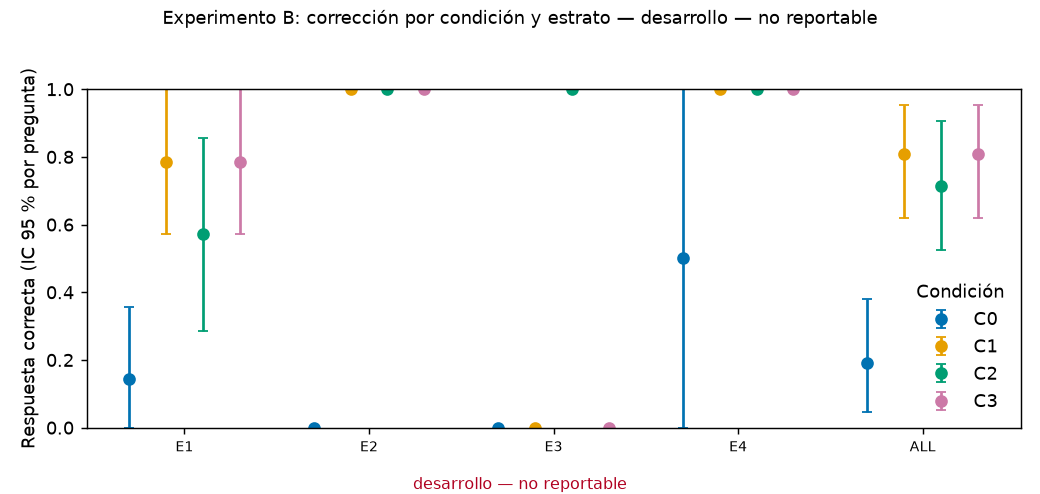

In [6]:
display(Image(filename=str(FIGURES_DIR / f"{NAME}-b-correct.png")))

**Lectura.** En el total de las 21 preguntas, C0 acierta 0,19; C1, 0,81; C2, 0,71 y C3, 0,81.
Recuperar contexto sube la corrección de forma clara frente a no recuperar nada. Los estratos
E2, E3 y E4 tienen entre 1 y 4 preguntas, por lo que sus cifras son anecdóticas; solo E1 (14
preguntas) permite una lectura, aún sin llegar al mínimo de 25.

---

# 4. La guarda de muestra mínima

**Pregunta.** ¿Qué veredictos se emiten con esta muestra?

**Por qué importa.** El 2026-11-02 se decidió que un veredicto exige el mínimo prerregistrado (`[question_bank].min_questions`, 25) de preguntas juzgadas, por condición y estrato. Antes de esa regla, la misma muestra de una pregunta en E3 daba H2 «contraria» y H4 «respaldada», lecturas sin sustento. Ahora las cifras se muestran, pero el veredicto es «muestra insuficiente».

In [7]:
verdict_frame(b_analysis)

,Hipótesis,Preguntas,Diferencia,Veredicto
0,"D16 (C2 - C1, E3)",1,"+1,00 [+1,00, +1,00]",muestra insuficiente
1,H4 wrong_among_answered (C1 - C2),1,"+1,00 [+1,00, +1,00]",muestra insuficiente
2,H2 (brecha E3 - E1),"E1 14, E3 1","-1,21 [-1,50, -0,93]",muestra insuficiente


In [8]:
paired = load_rehearsal_table(TABLES_DIR / f"{NAME}-b-paired.csv")
pd.crosstab(
    paired["descriptive"].map({False: "con veredicto", True: "descriptiva (C0)"}),
    paired["criterion"],
)

criterion,inconclusive,insufficient_sample,supported
descriptive,,,
con veredicto,0,21,0
descriptiva (C0),3,0,7


**Lectura.** Las comparaciones que deciden hipótesis (D16, H2, H4 y las secundarias C2 frente a
C1 y C3) quedan todas en «muestra insuficiente»; las comparaciones contra C0 son descriptivas
por diseño (ADR 0019) y no deciden ninguna hipótesis. Con el banco completo de evaluación la
regla no debería activarse.

---

# 5. Costo y latencia

**Qué se muestra.** Segundos por actividad: respuesta de cada condición, juez y extracción. Los modelos son locales, así que no hay costo monetario.

In [9]:
cost = load_rehearsal_table(TABLES_DIR / f"{NAME}-cost-latency.csv")
cost[["role", "model", "activity", "units", "mean_seconds", "total_seconds"]].round(1)

,role,model,activity,units,mean_seconds,total_seconds
0,answer,qwen3:8b,ensayo-b-es2015 / C0,21,3.8,80.2
1,answer,qwen3:8b,ensayo-b-es2015 / C1,21,5.7,119.0
2,answer,qwen3:8b,ensayo-b-es2015 / C2,21,20.7,435.7
3,answer,qwen3:8b,ensayo-b-es2015 / C3,21,18.6,390.2
4,judge,gpt-oss:20b,ensayo-b-es2015,84,7.4,622.4
5,extraction,qwen3:8b,OpenKOS completo ES2015 (ensayo-es2015),1,1545.5,1545.5


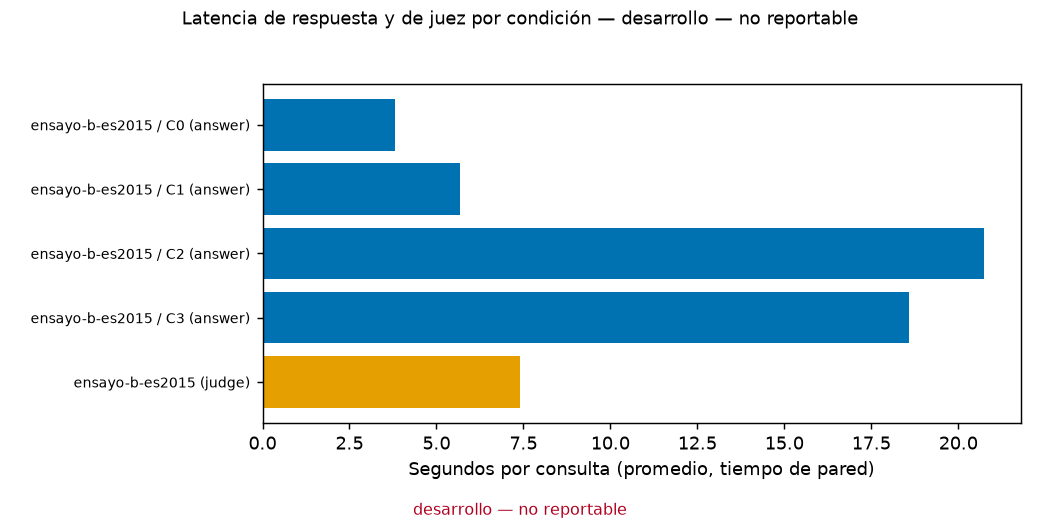

In [10]:
display(Image(filename=str(FIGURES_DIR / f"{NAME}-cost-latency.png")))

**Lectura.** Responder con C2 o C3 tarda unos 19 a 21 segundos por pregunta, frente a 4 de C0 y
6 de C1: la consulta a la base compilada es la parte cara de la respuesta. La extracción de la
base de ES2015 toma unos 26 minutos por corrida.

---

# 6. Qué se corrigió

La cadena no mostró errores de integración: ningún paso falló y las salidas de cada uno fueron
aceptadas por el siguiente. El ensayo sí llevó a una corrección de diseño en el análisis:

- **Veredictos con muestra insuficiente.** `afg experiment b-report` y `final-tables` emitían
  veredictos de D16, H2 y H4 sobre estratos con una sola pregunta. Ahora, si algún estrato
  involucrado tiene menos preguntas juzgadas que el mínimo prerregistrado en cualquiera de las
  condiciones comparadas, el veredicto es `insufficient_sample` («muestra insuficiente») y las
  cifras se siguen mostrando. La enmienda queda fechada el 2026-11-02 en los ADR 0010, 0017 y
  0018, con pruebas en `tests/test_experiment_b_analysis.py` y
  `tests/test_cli_experiment_b_analysis.py`.
- **`b-report` y `b-oe4-sheet` requieren `--questions`** con el CSV de la corrida; sin él, la
  hoja OE4 toma el banco principal por defecto.

# 7. Conclusión

El ensayo confirma que la cadena completa corre con el diseño vigente sobre ES2015 y deja los
tiempos de referencia para planificar la corrida formal. Las cifras descriptivas (una corrida,
21 preguntas) no son un resultado y no sustentan ninguna hipótesis.